**Assignment - EDA using Pandas**

***Instructions***
- Clone a copy of the assignment notebook in Google Colab.
- **Complete the tasks by filling in the code where indicated by TODO comments. Put each task in a new cell.**
- Run each cell to ensure your code works correctly.
- Pay attention to the output of each cell and interpret the results.
- For visualisation tasks, make sure to label axes, add titles, and choose appropriate colour schemes.
- After completing all tasks, review your findings and include notes of your insights gained from the EDA process as markdown notes for assessments.

In [1]:
# Titanic Dataset Exploratory Data Analysis

# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings so the tables are easier to read
pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 20)
sns.set_style('whitegrid')

## Task 1: Load the Titanic dataset

In [2]:
# Task 1: Load the Titanic dataset
# The file titanic.csv is placed in the same folder as the notebook (/content in Colab).
# If the file is not found, we fall back to the URL given in the assignment.
url = "https://web.stanford.edu/class/archive/cs/cs109/cs109.1166/stuff/titanic.csv"
file_path = "titanic.csv"

try:
    df = pd.read_csv(file_path)
    print(f"Loaded '{file_path}' from the local folder.")
except FileNotFoundError:
    print(f"'{file_path}' not found, loading the dataset from the URL instead.")
    df = pd.read_csv(url)
    # The URL version uses different column names, so we rename them
    df = df.rename(columns={'Siblings/Spouses Aboard': 'SibSp', 'Parents/Children Aboard': 'Parch'})

print("Shape (rows, columns):", df.shape)

Loaded 'titanic.csv' from the local folder.
Shape (rows, columns): (891, 12)


## Task 2: Inspect the data

In [3]:
# Task 2: Inspect the data
# First 5 rows
print("First 5 rows:")
print(df.head())

First 5 rows:
   PassengerId  Survived  Pclass                                               Name     Sex   Age  SibSp  Parch  \
0            1         0       3                            Braund, Mr. Owen Harris    male  22.0      1      0   
1            2         1       1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1      0   
2            3         1       3                             Heikkinen, Miss. Laina  female  26.0      0      0   
3            4         1       1       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1      0   
4            5         0       3                           Allen, Mr. William Henry    male  35.0      0      0   

             Ticket     Fare Cabin Embarked  
0         A/5 21171   7.2500   NaN        S  
1          PC 17599  71.2833   C85        C  
2  STON/O2. 3101282   7.9250   NaN        S  
3            113803  53.1000  C123        S  
4            373450   8.0500   NaN        S  


In [4]:
# Last 5 rows
print("Last 5 rows:")
print(df.tail())

Last 5 rows:
     PassengerId  Survived  Pclass                                      Name     Sex   Age  SibSp  Parch      Ticket  \
886          887         0       2                     Montvila, Rev. Juozas    male  27.0      0      0      211536   
887          888         1       1              Graham, Miss. Margaret Edith  female  19.0      0      0      112053   
888          889         0       3  Johnston, Miss. Catherine Helen "Carrie"  female   NaN      1      2  W./C. 6607   
889          890         1       1                     Behr, Mr. Karl Howell    male  26.0      0      0      111369   
890          891         0       3                       Dooley, Mr. Patrick    male  32.0      0      0      370376   

      Fare Cabin Embarked  
886  13.00   NaN        S  
887  30.00   B42        S  
888  23.45   NaN        S  
889  30.00  C148        C  
890   7.75   NaN        Q  


In [5]:
# Data types of each column
print("Data types:")
print(df.dtypes)

Data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


In [6]:
# Summary statistics of the numerical columns
print("Summary statistics:")
print(df.describe().round(2))

# Check missing values in each column
print("\nMissing values per column:")
print(df.isnull().sum())

Summary statistics:
       PassengerId  Survived  Pclass     Age   SibSp   Parch    Fare
count       891.00    891.00  891.00  714.00  891.00  891.00  891.00
mean        446.00      0.38    2.31   29.70    0.52    0.38   32.20
std         257.35      0.49    0.84   14.53    1.10    0.81   49.69
min           1.00      0.00    1.00    0.42    0.00    0.00    0.00
25%         223.50      0.00    2.00   20.12    0.00    0.00    7.91
50%         446.00      0.00    3.00   28.00    0.00    0.00   14.45
75%         668.50      1.00    3.00   38.00    1.00    0.00   31.00
max         891.00      1.00    3.00   80.00    8.00    6.00  512.33

Missing values per column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


**Notes (Task 2):** The dataset has 891 passengers and 12 columns. Only about 38% of the passengers survived (mean of `Survived` = 0.38). The average age is about 29.7 years. `Fare` is very spread out: the median is 14.45 but the maximum is 512.33, so there are some very expensive tickets. Three columns have missing values: `Age` (177), `Cabin` (687) and `Embarked` (2).

## Task 3: Clean and preprocess the data

In [7]:
# Task 3: Clean and preprocess the data

# New categorical feature 'PclassCategory' from 'Pclass' (1, 2, 3 -> First, Second, Third)
df['PclassCategory'] = df['Pclass'].map({1: 'First', 2: 'Second', 3: 'Third'}).astype('category')

# New categorical feature 'CabinCategory' from 'Cabin'
# The first letter of the cabin is the deck. Missing cabins become 'Unknown'.
if 'Cabin' in df.columns:
    df['CabinCategory'] = df['Cabin'].fillna('Unknown').str[0].replace('U', 'Unknown').astype('category')
else:
    df['CabinCategory'] = 'Unknown'

print(df[['Pclass', 'PclassCategory', 'Cabin', 'CabinCategory']].head(8))
print("\nPassengers per cabin category:")
print(df['CabinCategory'].value_counts())

   Pclass PclassCategory Cabin CabinCategory
0       3          Third   NaN       Unknown
1       1          First   C85             C
2       3          Third   NaN       Unknown
3       1          First  C123             C
4       3          Third   NaN       Unknown
5       3          Third   NaN       Unknown
6       1          First   E46             E
7       3          Third   NaN       Unknown

Passengers per cabin category:
CabinCategory
Unknown    687
C           59
B           47
D           33
E           32
A           15
F           13
G            4
T            1
Name: count, dtype: int64


In [8]:
# Handle missing values in the 'Age' column (use mean age)
print("Missing ages before:", df['Age'].isnull().sum())
mean_age = df['Age'].mean()
df['Age'] = df['Age'].fillna(mean_age)
print(f"Missing ages are filled with the mean age: {mean_age:.2f}")
print("Missing ages after:", df['Age'].isnull().sum())

Missing ages before: 177
Missing ages are filled with the mean age: 29.70
Missing ages after: 0


In [9]:
# Create a 'Family' feature by combining 'SibSp' and 'Parch'
# Family = number of siblings/spouses + number of parents/children on board
df['Family'] = df['SibSp'] + df['Parch']
print(df[['Name', 'SibSp', 'Parch', 'Family']].head())
print("\nFamily size counts:")
print(df['Family'].value_counts().sort_index())

                                                Name  SibSp  Parch  Family
0                            Braund, Mr. Owen Harris      1      0       1
1  Cumings, Mrs. John Bradley (Florence Briggs Th...      1      0       1
2                             Heikkinen, Miss. Laina      0      0       0
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)      1      0       1
4                           Allen, Mr. William Henry      0      0       0

Family size counts:
Family
0     537
1     161
2     102
3      29
4      15
5      22
6      12
7       6
10      7
Name: count, dtype: int64


**Notes (Task 3):** Most passengers (687 of 891) have no cabin recorded, so `CabinCategory` is mostly 'Unknown'. The 177 missing ages were replaced by the mean age (29.70). This keeps all the rows, but it creates a peak at 29.7 in the age distribution. Most passengers travelled alone (Family = 0).

## Task 4: Identify specific data points

In [10]:
# Task 4: Identify specific data points

# Passengers with the highest fare
highest_fare_passengers = df[df['Fare'] == df['Fare'].max()]
print("Passengers with the highest fare:")
print(highest_fare_passengers[['Name', 'Pclass', 'Fare', 'Survived']])

Passengers with the highest fare:
                                   Name  Pclass      Fare  Survived
258                    Ward, Miss. Anna       1  512.3292         1
679  Cardeza, Mr. Thomas Drake Martinez       1  512.3292         1
737              Lesurer, Mr. Gustave J       1  512.3292         1


In [11]:
# Passengers with the largest family size
largest_family_passengers = df[df['Family'] == df['Family'].max()]
print(f"Largest family size: {df['Family'].max()}")
print(largest_family_passengers[['Name', 'Pclass', 'Family', 'Survived']])

Largest family size: 10


                                  Name  Pclass  Family  Survived
159         Sage, Master. Thomas Henry       3      10         0
180       Sage, Miss. Constance Gladys       3      10         0
201                Sage, Mr. Frederick       3      10         0
324           Sage, Mr. George John Jr       3      10         0
792            Sage, Miss. Stella Anna       3      10         0
846           Sage, Mr. Douglas Bullen       3      10         0
863  Sage, Miss. Dorothy Edith "Dolly"       3      10         0


**Notes (Task 4):** Three first-class passengers paid the highest fare (512.33) and all three survived. The largest family is the Sage family (10 relatives on board), in third class. None of the 7 Sage members in this dataset survived.

## Task 5: Demonstrate Pandas Series and DataFrame functionalities

In [12]:
# Task 5: Pandas Series and DataFrame functionalities

# Create a Pandas Series of passenger names
names_series = pd.Series(df['Name'].values, name='Name')
print("Type:", type(names_series))
print("First 3 names:")
print(names_series.head(3))

# Indexing on a Series
print("\nFirst name (index 0):", names_series[0])
print("Last name (iloc[-1]):", names_series.iloc[-1])
print("Number of names:", names_series.size)

Type:

 <class 'pandas.core.series.Series'>
First 3 names:
0                              Braund, Mr. Owen Harris
1    Cumings, Mrs. John Bradley (Florence Briggs Th...
2                               Heikkinen, Miss. Laina
Name: Name, dtype: object

First name (index 0): Braund, Mr. Owen Harris
Last name (iloc[-1]): Dooley, Mr. Patrick
Number of names: 891


In [13]:
# Create a DataFrame of passenger names and ages
names_ages_df = df[['Name', 'Age']].copy()
print(names_ages_df.head())

# Indexing and slicing
print("\nRows 10 to 14 with iloc:")
print(names_ages_df.iloc[10:15])
print("\nAge of the passenger with index 5 with loc:", names_ages_df.loc[5, 'Age'])

# Slice the DataFrame to show only passengers older than 50
older_passengers = names_ages_df[names_ages_df['Age'] > 50]
print(f"\nPassengers older than 50: {len(older_passengers)}")
print(older_passengers.head(10))

                                                Name   Age
0                            Braund, Mr. Owen Harris  22.0
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  38.0
2                             Heikkinen, Miss. Laina  26.0
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  35.0
4                           Allen, Mr. William Henry  35.0

Rows 10 to 14 with iloc:
                                    Name   Age
10       Sandstrom, Miss. Marguerite Rut   4.0
11              Bonnell, Miss. Elizabeth  58.0
12        Saundercock, Mr. William Henry  20.0
13           Andersson, Mr. Anders Johan  39.0
14  Vestrom, Miss. Hulda Amanda Adolfina  14.0

Age of the passenger with index 5 with loc: 29.69911764705882

Passengers older than 50: 64
                                 Name   Age
6             McCarthy, Mr. Timothy J  54.0
11           Bonnell, Miss. Elizabeth  58.0
15   Hewlett, Mrs. (Mary D Kingcome)   55.0
33              Wheadon, Mr. Edward H  66.0
54     Ostby, Mr. Engelha

## Task 6: Multi-indexing

In [14]:
# Task 6: Multi-index DataFrame of survival rates grouped by 'Sex' and 'Pclass'
multi_index_df = df.groupby(['Sex', 'Pclass'])[['Survived']].mean().round(3)
multi_index_df.columns = ['SurvivalRate']
print(multi_index_df)
print("\nIndex levels:", multi_index_df.index.names)

# Select with the multi-index
print("\nFemale passengers only:")
print(multi_index_df.loc['female'])
print("\nFirst class only (xs on level 'Pclass'):")
print(multi_index_df.xs(1, level='Pclass'))

               SurvivalRate
Sex    Pclass              
female 1              0.968
       2              0.921
       3              0.500
male   1              0.369
       2              0.157
       3              0.135

Index levels: ['Sex', 'Pclass']

Female passengers only:
        SurvivalRate
Pclass              
1              0.968
2              0.921
3              0.500

First class only (xs on level 'Pclass'):
        SurvivalRate
Sex                 
female         0.968
male           0.369


**Notes (Task 6):** The multi-index shows that sex and class work together. Almost all first-class women survived (96.8%), but only 13.5% of third-class men did.

## Task 7: Visualizations

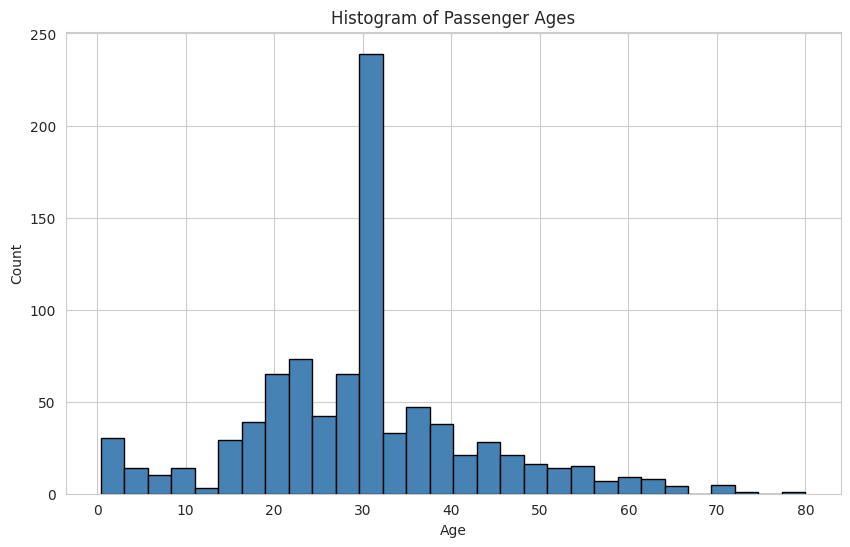

In [15]:
# Histogram of passenger ages
plt.figure(figsize=(10, 6))
plt.hist(df['Age'], bins=30, color='steelblue', edgecolor='black')
plt.title('Histogram of Passenger Ages')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

**Notes:** Most passengers were between 20 and 40 years old. The tall bar near 30 comes from the 177 missing ages that were filled with the mean (29.7). There are also some children under 10 and only a few passengers over 60.

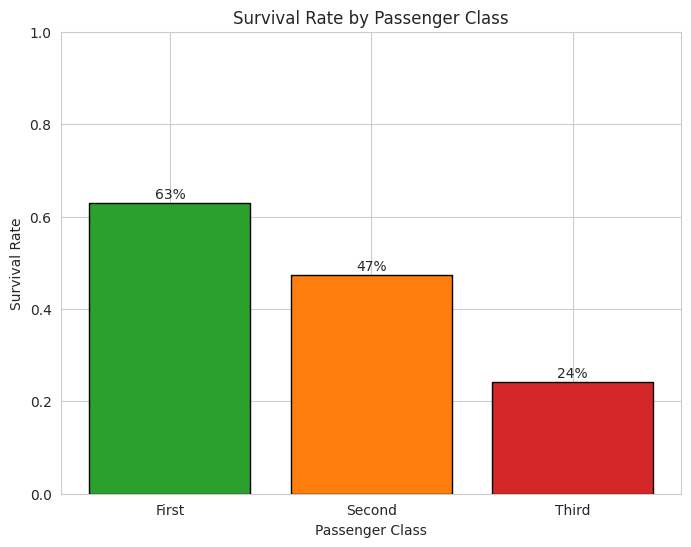

In [16]:
# Bar plot of survival rates by passenger class
survival_rate_class = df.groupby('Pclass')['Survived'].mean()
plt.figure(figsize=(8, 6))
bars = plt.bar(['First', 'Second', 'Third'], survival_rate_class.values,
               color=['#2ca02c', '#ff7f0e', '#d62728'], edgecolor='black')
for bar, rate in zip(bars, survival_rate_class.values):
    plt.text(bar.get_x() + bar.get_width() / 2, rate + 0.01, f"{rate:.0%}", ha='center')
plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.ylim(0, 1)
plt.show()

**Notes:** The survival rate goes down with class: 63% in first class, 47% in second class and only 24% in third class.

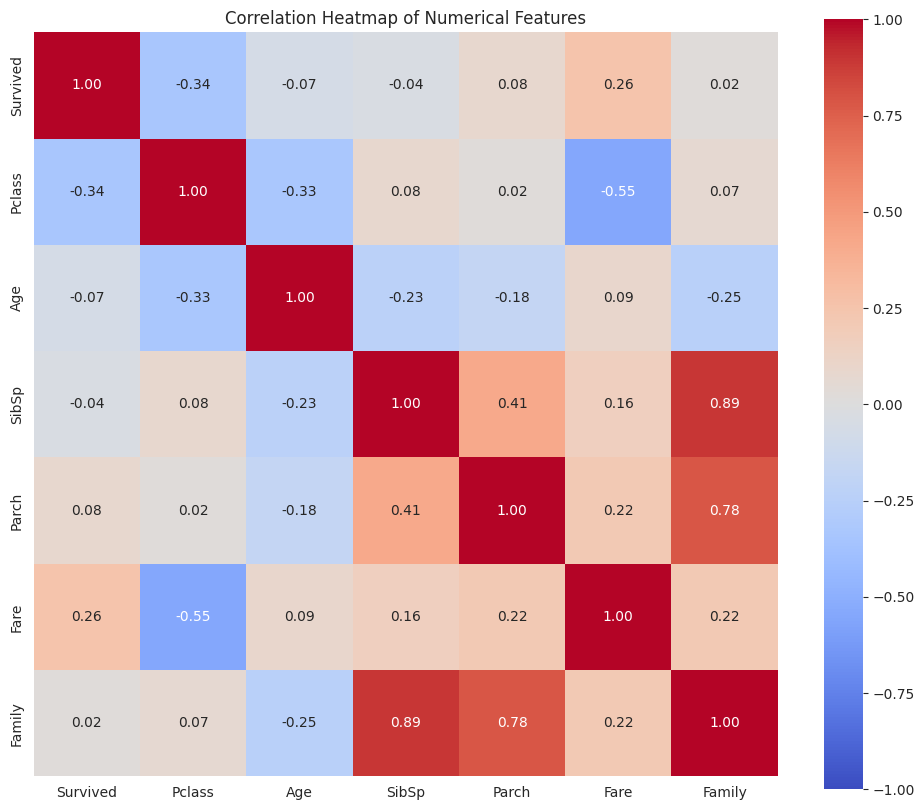

In [17]:
# Heatmap of correlation between numerical features
numeric_cols = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Family']
corr = df[numeric_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

**Notes:** `Survived` has a negative correlation with `Pclass` (-0.34): a higher class number (cheaper class) means a lower chance of survival. It has a positive correlation with `Fare` (+0.26). `Pclass` and `Fare` are strongly negatively correlated (-0.55), which makes sense because first class was expensive. `Family` is almost the sum of `SibSp` and `Parch`, so it is strongly correlated with both.

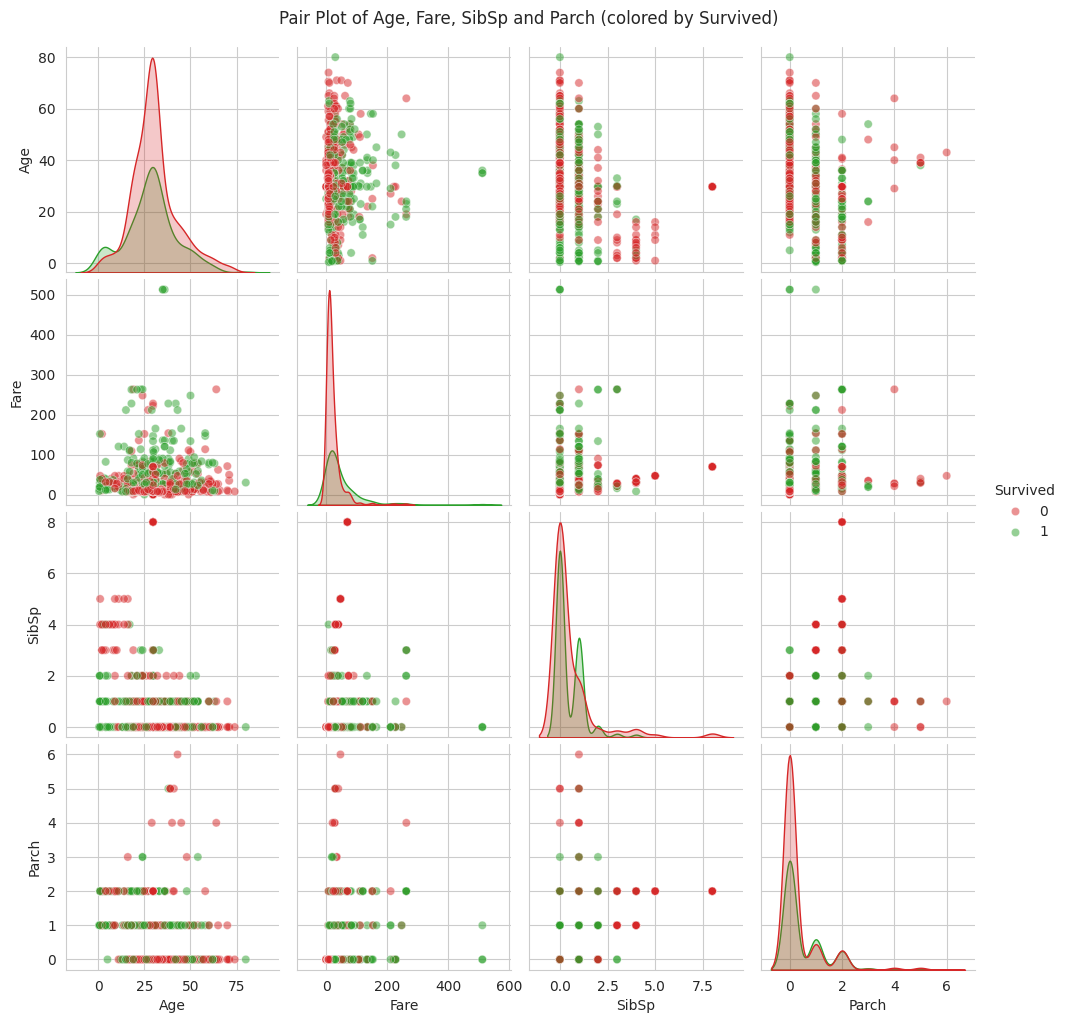

In [18]:
# Pair plot of 'Age', 'Fare', 'SibSp' and 'Parch', colored by 'Survived'
pair = sns.pairplot(df[['Age', 'Fare', 'SibSp', 'Parch', 'Survived']], hue='Survived',
                    palette={0: '#d62728', 1: '#2ca02c'}, plot_kws={'alpha': 0.5})
pair.fig.suptitle('Pair Plot of Age, Fare, SibSp and Parch (colored by Survived)', y=1.02)
plt.show()

**Notes:** Survivors (green) are more common among passengers with a high fare. Passengers with large families (high SibSp or Parch) are mostly red, so big families had a lower chance of survival.

## Task 8: Analyze survival rates

In [19]:
# Task 8: Survival rates by sex
survival_by_sex = df.groupby('Sex')['Survived'].mean()
print("Survival rate by sex:")
print((survival_by_sex * 100).round(1).astype(str) + ' %')

# Survival rates by passenger class
survival_by_class = df.groupby('PclassCategory', observed=True)['Survived'].mean()
print("\nSurvival rate by passenger class:")
print((survival_by_class * 100).round(1).astype(str) + ' %')

Survival rate by sex:
Sex
female    74.2 %
male      18.9 %
Name: Survived, dtype: object

Survival rate by passenger class:
PclassCategory
First     63.0 %
Second    47.3 %
Third     24.2 %
Name: Survived, dtype: object


**Notes (Task 8):** Women survived much more than men (74.2% vs 18.9%), which matches the "women and children first" rule. Class mattered too: 63.0% of first-class passengers survived, but only 24.2% of third-class passengers.

## Task 9: Analyze age distribution

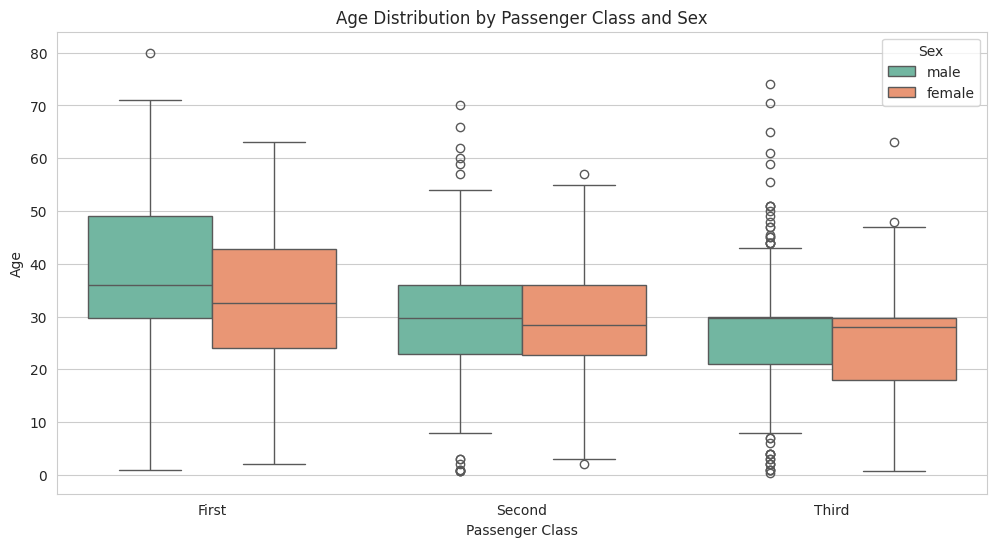

In [20]:
# Task 9: Box plot of age distribution by passenger class and sex
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='PclassCategory', y='Age', hue='Sex', palette='Set2')
plt.title('Age Distribution by Passenger Class and Sex')
plt.xlabel('Passenger Class')
plt.ylabel('Age')
plt.legend(title='Sex')
plt.show()

**Notes (Task 9):** First-class passengers were the oldest (median 32.5 for women and 36 for men). In every class, men were a little older than women. Third class has many children and young adults, but also most of the missing ages (136 of 177), so its medians are pulled to the filled mean (29.7).

## Task 10: Analyze fare distribution

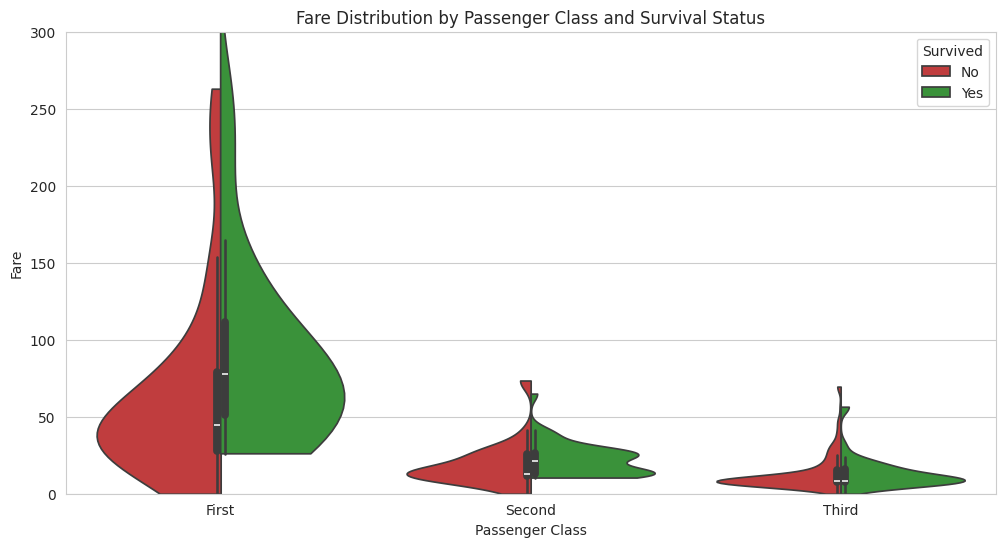

EDA tasks completed.


In [21]:
# Task 10: Violin plot of fare distribution by passenger class and survival status
# A text label (No / Yes) makes the legend clearer than 0 / 1
df['SurvivedLabel'] = df['Survived'].map({0: 'No', 1: 'Yes'})

plt.figure(figsize=(12, 6))
sns.violinplot(data=df, x='PclassCategory', y='Fare', hue='SurvivedLabel', split=True,
               palette={'No': '#d62728', 'Yes': '#2ca02c'}, cut=0, density_norm='width')
plt.ylim(0, 300)   # 3 tickets at 512 are above this limit, they are shown in Task 4
plt.title('Fare Distribution by Passenger Class and Survival Status')
plt.xlabel('Passenger Class')
plt.ylabel('Fare')
plt.legend(title='Survived')
plt.show()

print("EDA tasks completed.")

**Notes (Task 10):** First-class fares are much higher and more spread out (median 60.29) than second-class (14.25) and third-class (8.05) fares. In first class, survivors tend to have paid more than non-survivors. In third class, fares are low and close together for everyone. The y-axis stops at 300 so the shapes are readable; the 3 tickets at 512.33 are listed in Task 4.

## Summary of EDA insights

1. **Overall survival:** only 342 of 891 passengers (38.4%) survived.
2. **Sex was the strongest factor:** 74.2% of women survived against 18.9% of men.
3. **Class mattered:** survival dropped from 63.0% (first) to 47.3% (second) and 24.2% (third). First-class women had the best chance (96.8%), third-class men the worst (13.5%).
4. **Money and survival:** higher fares are linked to survival (correlation +0.26), mostly because expensive tickets were first class.
5. **Family size:** very large families had low survival, for example none of the Sage family (10 relatives) survived.
6. **Age:** most passengers were 20 to 40 years old. First-class passengers were the oldest group.
7. **Data quality:** `Cabin` is missing for 77% of passengers, so `CabinCategory` should be used carefully. Filling `Age` with the mean keeps all rows but creates an artificial peak at 29.7, so a better method (for example the median age by class and sex) could be used in a future analysis.